In [1]:
import os
import glob, numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt, cartopy.crs as ccrs
import intake

REF  = "/home/c3xiang/jcm/jcm_runs/reference"
CTRL = "/home/c3xiang/jcm/jcm_runs/control"
PERIOD = slice("2005-01-01", "2014-12-31")      # matches the JCM forcing
tgt = xr.open_dataset(sorted(glob.glob(f"{CTRL}/speedy-t31_monthly_*.nc"))[0])[["lat", "lon"]]

### Variables

- tas: surface temp
- pr: precipitation
- toa_in_sw: incoming sunlight at top of atmosphere
- toa_net_sw: net sunlight at top (incoming - reflected)
- toa_net_lw: net longwave( heat) radiation at top
- ta: air temp at each pressure level (surface --> stratosphere)
- ua: east-west wind at each level (postivie = from west)
- va: noth south wind at each level

In [2]:
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
def gmean(da):
    return float(da.weighted(np.cos(np.deg2rad(da.lat))).mean(["lat", "lon"]))

def wrap_lon(da):
    """Add a copy of the last/first longitude on either side so interpolation reaches 0° and 360°."""
    left  = da.isel(lon=-1).assign_coords(lon=da.lon[-1] - 360)
    right = da.isel(lon=0).assign_coords(lon=da.lon[0] + 360)
    return xr.concat([left, da, right], dim="lon")

### ERA5 Climatology

Average calendar months + regrids to t31

In [4]:
ERA_FILE = f"{REF}/era5_clim_2005-2014_t31.nc"

if os.path.exists(ERA_FILE):
    era = xr.open_dataset(ERA_FILE)
    print("Loaded saved ERA5 climatology")
else:
    clim = {}
    for name in ["tas", "pr", "toa_net_sw", "toa_net_lw", "toa_in_sw", "ta", "ua", "va"]:
        ds = xr.open_mfdataset(sorted(glob.glob(f"{REF}/era5_years/{name}_*.nc")), combine="by_coords")
        da = ds[list(ds.data_vars)[0]].rename({"latitude": "lat", "longitude": "lon"}).sortby("lat")
        if "level" in da.dims:
            da = da.rename({"level": "plev"})
        c = da.groupby("time.month").mean("time")
        clim[name] = wrap_lon(c).interp(lat=tgt.lat, lon=tgt.lon).load()
        print(name, "done")
    era = xr.Dataset(clim)
    
    era["pr"] = era["pr"] * 86400                              # → mm/day
    raw = gmean(era["toa_in_sw"].mean("month"))
    for sec in [1, 3600, 86400]:
        if 250 < raw / sec < 450:
            era["toa_in_sw"] = era["toa_in_sw"] / sec; print("tisr ÷", sec); break
    era["toa_up_sw"] = era["toa_in_sw"] - era["toa_net_sw"]
    era["olr"] = -era["toa_net_lw"]
    era.to_netcdf(ERA_FILE)

Loaded saved ERA5 climatology


In [5]:
#check regrid values
for v in ["tas", "pr", "toa_in_sw", "toa_up_sw", "olr"]:
    print(f"{v:10s} {gmean(era[v].mean('month')):8.2f}")
print("net TOA", round(gmean((era.toa_in_sw - era.toa_up_sw - era.olr).mean("month")), 2))

tas          287.55
pr             2.95
toa_in_sw    340.37
toa_up_sw     97.71
olr          241.98
net TOA 0.68


### NorESM2-LM Climatology

In [6]:
NOR_FILE = f"{REF}/noresm2lm_hist_clim_2005-2014_t31.nc"

if os.path.exists(NOR_FILE):
    nor = xr.open_dataset(NOR_FILE)
    print("Loaded saved NorESM2-LM climatology")
else:
    cat = intake.open_esm_datastore("https://storage.googleapis.com/cmip6/pangeo-cmip6.json")
    sub = cat.search(source_id="NorESM2-LM", experiment_id="historical", member_id="r1i1p1f1",
                     table_id="Amon", variable_id=["tas","pr","ta","ua","va","rsdt","rsut","rlut"])
    nor = xr.merge(list(sub.to_dataset_dict(xarray_open_kwargs={"consolidated": True}).values()),
                   compat="override").sel(time=PERIOD)
    nor = nor.groupby("time.month").mean("time").interp(lat=tgt.lat, lon=tgt.lon)
    nor["pr"] = nor["pr"] * 86400
    nor = nor.assign_coords(plev=nor.plev / 100)               # Pa → hPa
    nor = nor.rename({"rsdt": "toa_in_sw", "rsut": "toa_up_sw", "rlut": "olr"}).load()
    nor.to_netcdf(NOR_FILE)
    print("Built and saved NorESM2-LM climatology")

Loaded saved NorESM2-LM climatology


In [7]:
#find names of JCM vars
jds = xr.open_mfdataset(sorted(glob.glob(f"{CTRL}/speedy-t31_monthly_*.nc")))
def find(*w): return [v for v in jds.data_vars if all(x in v.lower() for x in w)]
for kw in ["temp", "precip", "rain", "wind", "toa", "top", "olr", "flux", "solar"]:
    print(kw, find(kw))

temp ['surface_exchange.air_potential_temperature', 'temperature']
precip ['surface_exchange.precipitation']
rain []
wind ['v_wind', 'u_wind', 'surface_exchange.wind_v', 'surface_exchange.wind_speed', 'surface_exchange.wind_u']
toa []
top ['shortwave_rad.ftop', 'longwave_rad.ftop']
olr []
flux ['surface_flux.rlds', 'surface_flux.rlus', 'mod_radcon.flux.2', 'surface_flux.evap', 'surface_flux.rlns', 'surface_flux.u0', 'surface_exchange.net_heat_flux', 'mod_radcon.flux.1', 'surface_flux.hfluxn', 'surface_flux.tsfc', 'surface_flux.v0', 'mod_radcon.flux.3', 'surface_flux.tskin', 'surface_flux.shf', 'surface_exchange.latent_heat_flux', 'mod_radcon.flux.0', 'surface_flux.t0', 'surface_exchange.sensible_heat_flux', 'surface_flux.vstr', 'surface_flux.ustr']
solar []


In [8]:
V = dict(
    tas = "surface_flux.t0",               # SPEEDY's near-surface air temperature (K)
    pr  = "surface_exchange.precipitation",
    ta  = "temperature",                   # 3-D air temperature on sigma levels
    ua  = "u_wind",
    va  = "v_wind",
    toa_net_sw = "shortwave_rad.ftop",     # likely NET downward SW at the top (incoming − reflected)
    olr        = "longwave_rad.ftop",      # likely outgoing longwave at the top
)

In [9]:
for v in ["surface_flux.t0", "surface_exchange.precipitation",
          "shortwave_rad.ftop", "longwave_rad.ftop"]:
    print(v, dict(jds[v].attrs))

print("\nAll shortwave_rad / longwave_rad variables:")
for v in jds.data_vars:
    if v.startswith(("shortwave_rad.", "longwave_rad.")):
        print(f"  {v:40s} {jds[v].dims}  {jds[v].attrs.get('long_name', '')}  {jds[v].attrs.get('units', '')}")

surface_flux.t0 {'units': 'K', 'description': 'Near-surface temperature', 'cell_methods': 'time: mean'}
surface_exchange.precipitation {'units': 'kg m-2 s-1', 'standard_name': 'precipitation_flux', 'long_name': 'total precipitation (rain + snow, positive down)', 'description': 'total precipitation reaching the surface (rain + snow, convective + stratiform), positive down', 'cell_methods': 'time: mean'}
shortwave_rad.ftop {'units': 'W/m²', 'description': 'Net downward flux at top of atmosphere', 'cell_methods': 'time: mean'}
longwave_rad.ftop {'units': 'W/m²', 'description': 'Outgoing flux of long-wave radiation at the top of the atmosphere', 'cell_methods': 'time: mean'}

All shortwave_rad / longwave_rad variables:
  shortwave_rad.qcloud                     ('time', 'lon', 'lat')    1
  shortwave_rad.cloudstr                   ('time', 'lon', 'lat')    1
  shortwave_rad.heating_rate               ('time', 'level', 'lon', 'lat')    K/s
  shortwave_rad.gse                        ('time',

In [10]:
late = jds.sel(time=slice("2001", "2010"))
for v in ["surface_flux.t0", "surface_exchange.precipitation",
          "shortwave_rad.ftop", "longwave_rad.ftop"]:
    print(f"{v:35s} {gmean(late[v].mean('time')):10.5f}")

surface_flux.t0                      287.95019
surface_exchange.precipitation         0.00003
shortwave_rad.ftop                   241.59024
longwave_rad.ftop                    236.61112


In [11]:
nor_check = nor.squeeze(drop=True)
nor_check = nor_check.assign(toa_net_sw=nor_check.toa_in_sw - nor_check.toa_up_sw)   # net SW = incoming − reflected

for v in ["tas", "pr", "toa_in_sw", "toa_net_sw", "toa_up_sw", "olr"]:
    print(f"{v:11s} {gmean(nor_check[v].mean('month')):9.2f}")
print("net TOA    ", round(gmean((nor_check.toa_in_sw - nor_check.toa_up_sw - nor_check.olr).mean("month")), 2))
print("plev (hPa):", nor_check.plev.values)

tas            288.34
pr               2.86
toa_in_sw      340.23
toa_net_sw     238.17
toa_up_sw      102.06
olr            237.53
net TOA     0.65
plev (hPa): [1000.  925.  850.  700.  600.  500.  400.  300.  250.  200.  150.  100.
   70.   50.   30.   20.   10.    5.    1.]


### JCM Climatology

In [12]:
V["toa_in_sw"] = "shortwave_rad.fsol"        

jcm = (jds.sel(time=slice("2001", "2010"))[list(V.values())]
          .rename({v: k for k, v in V.items()})
          .groupby("time.month").mean("time")
          .transpose("month", ..., "lat", "lon").load())

jcm["pr"] = jcm["pr"] * 86400                 
jcm["toa_up_sw"] = jcm["toa_in_sw"] - jcm["toa_net_sw"]   # reflected sunlight
jcm = jcm.assign_coords(plev=("level", jcm.level.values * 1000))

In [13]:
#check values
for v in ["tas", "pr", "toa_in_sw", "toa_net_sw", "toa_up_sw", "olr"]:
    print(f"{v:11s} {gmean(jcm[v].mean('month')):9.2f}")
print("net TOA    ", round(gmean((jcm.toa_in_sw - jcm.toa_up_sw - jcm.olr).mean("month")), 2))
print("levels:", jcm.level.values, "→ plev:", jcm.plev.values)

tas            287.95
pr               2.92
toa_in_sw      342.05
toa_net_sw     241.59
toa_up_sw      100.46
olr            236.61
net TOA     4.98
levels: [0.9375 0.8125 0.6875 0.5625 0.4375 0.3125 0.1875 0.0625] → plev: [937.5 812.5 687.5 562.5 437.5 312.5 187.5  62.5]


In [14]:
#align 48 x96 grid w/ 12 months
jcm.to_netcdf(f"{REF}/jcm_control_clim_2001-2010.nc")

era = xr.open_dataset(f"{REF}/era5_clim_2005-2014_t31.nc").squeeze(drop=True)
nor = xr.open_dataset(f"{REF}/noresm2lm_hist_clim_2005-2014_t31.nc").squeeze(drop=True)
jcm = jcm.squeeze(drop=True)

era = era.assign_coords(lat=jcm.lat, lon=jcm.lon)
nor = nor.assign_coords(lat=jcm.lat, lon=jcm.lon)

nor["plev"].attrs = {"units": "hPa", "long_name": "pressure"}
jcm["plev"].attrs = {"units": "hPa", "long_name": "approx. pressure (σ × 1000)"}

for name, d in [("JCM", jcm), ("ERA5", era), ("NorESM2-LM", nor)]:
    print(name, dict(d.sizes))

JCM {'month': 12, 'lat': 48, 'lon': 96, 'level': 8}
ERA5 {'month': 12, 'lat': 48, 'lon': 96, 'plev': 12}
NorESM2-LM {'month': 12, 'plev': 19, 'lat': 48, 'lon': 96, 'bnds': 2}


### Helper functions

In [15]:
W = np.cos(np.deg2rad(jcm.lat))

def season(da, s):
    months = {"ANN": list(range(1, 13)), "DJF": [12, 1, 2], "JJA": [6, 7, 8]}[s]
    return da.sel(month=months).mean("month")

def pattern_corr(a, b):
    w = W.broadcast_like(a)
    am, bm = (a * w).sum() / w.sum(), (b * w).sum() / w.sum()
    cov = (w * (a - am) * (b - bm)).sum()
    return float(cov / np.sqrt((w * (a - am) ** 2).sum() * (w * (b - bm) ** 2).sum()))

def gm(da):
    return float(da.weighted(W).mean(["lat", "lon"]))

In [16]:
def check(d):
    d = d.assign(toa_net_sw=d.toa_in_sw - d.toa_up_sw)
    out = {v: gmean(d[v].mean("month")) for v in ["tas", "pr", "toa_in_sw", "toa_net_sw", "toa_up_sw", "olr"]}
    out["net TOA"] = out["toa_in_sw"] - out["toa_up_sw"] - out["olr"]
    return out

pd.DataFrame({"JCM": check(jcm), "ERA5": check(era), "NorESM2-LM": check(nor)}).round(2)

,JCM,ERA5,NorESM2-LM
tas,287.95,287.55,288.34
pr,2.92,2.95,2.86
toa_in_sw,342.05,340.37,340.23
toa_net_sw,241.59,242.66,238.17
toa_up_sw,100.46,97.71,102.06
olr,236.61,241.98,237.53
net TOA,4.98,0.68,0.65


### Map Comparisons:

#### tas: 
- global pattern is generally good (biases are less than 1K)
- poles are too warm when compared to both ERA5 and JCM.(maybe something to do with how SPEEDY represents sst and sea ice?)
- some bias in mountainous regions (T31 resolution might not capture elevation/height differences)
- pole that is too warm swaps between DJF and JJA

#### precipitation:
- does well on global means (JCM 2.92mm/day, ERA5 2.95mm/day, 2.86mm/day)
- actual spatial pattern is a lot weaker (0.6, 0.62)
- too dry over South America and Southeast Asia
- line patterns over oceans in the south

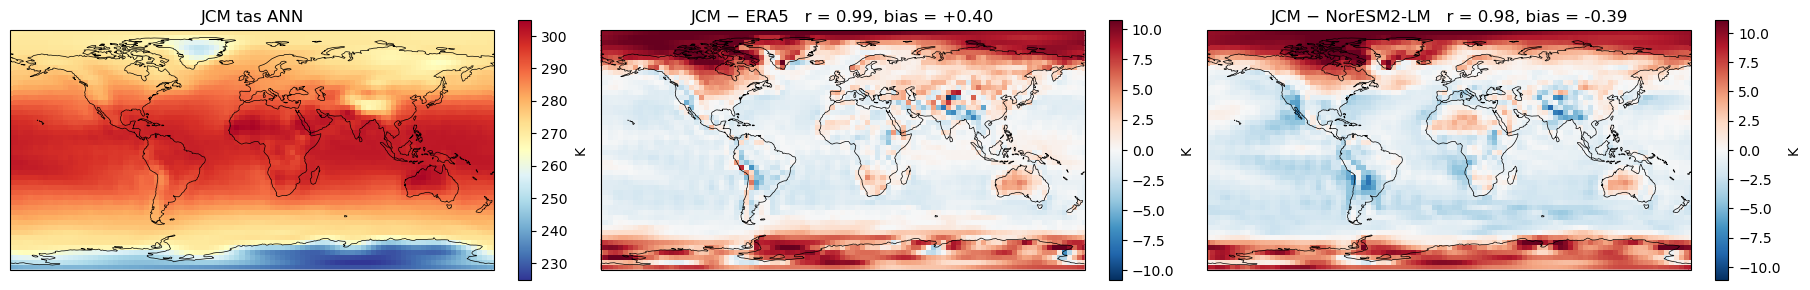

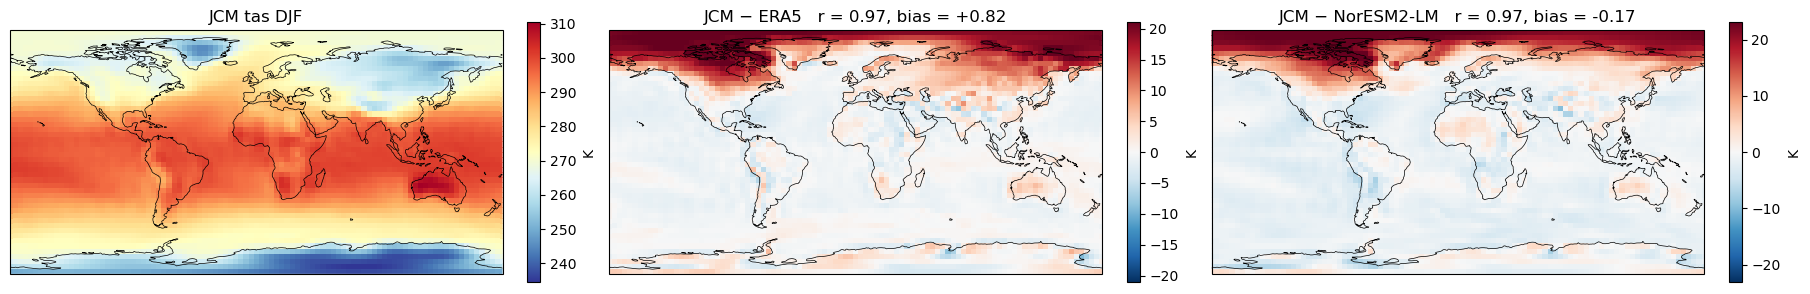

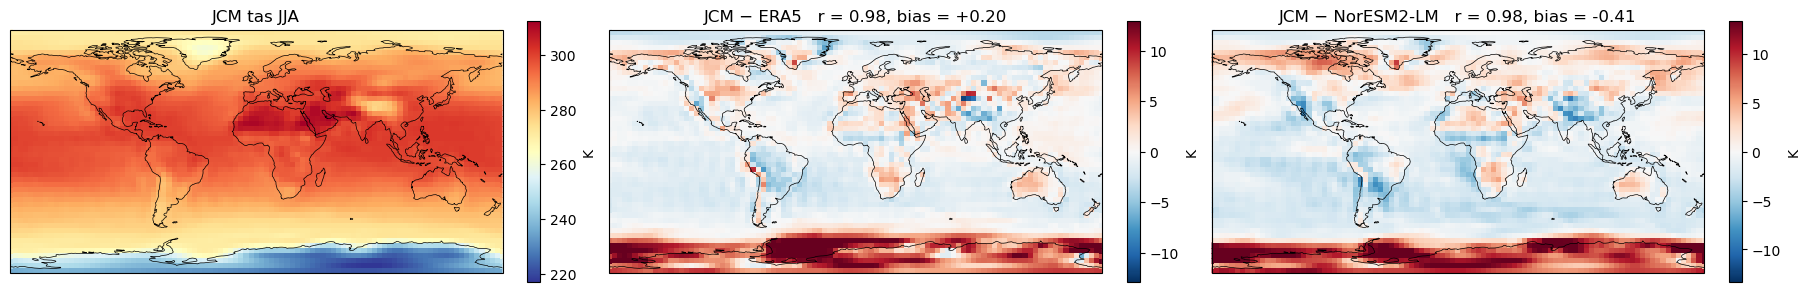

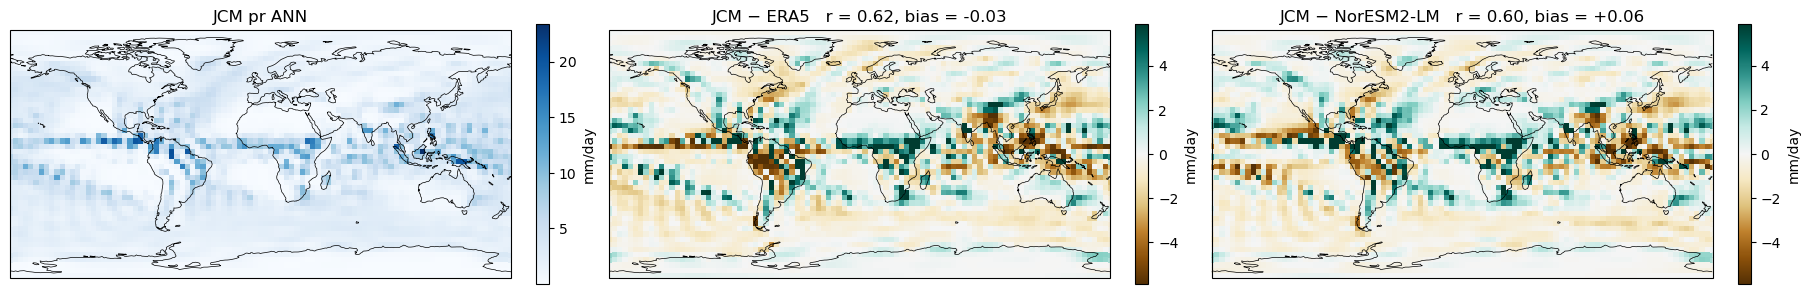

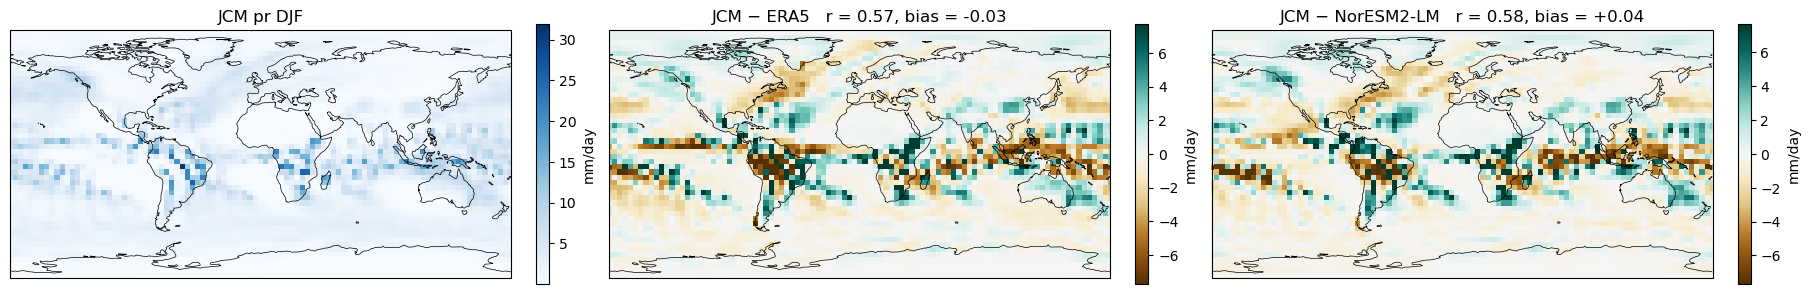

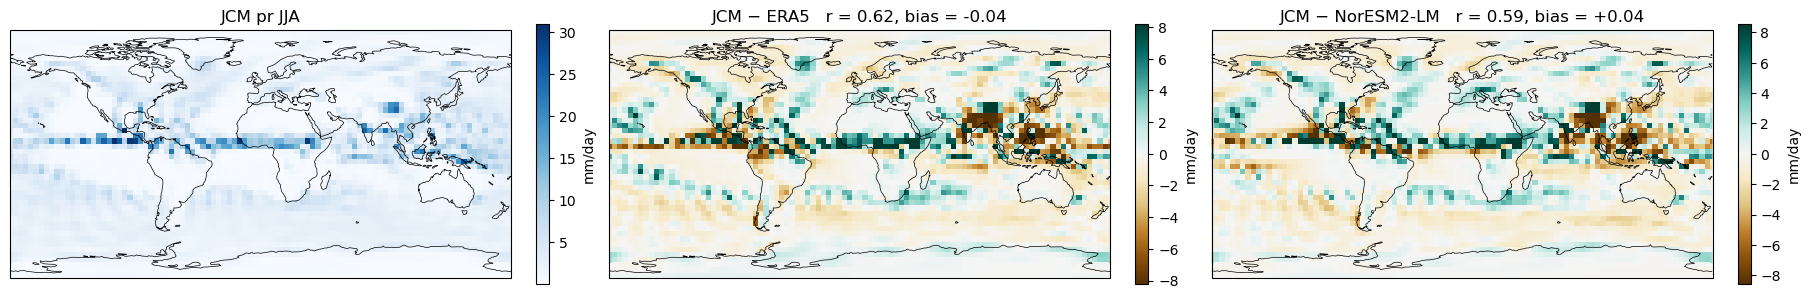

In [17]:
import os; os.makedirs("figures", exist_ok=True)
REFS = {"ERA5": era, "NorESM2-LM": nor}
STYLE = {"tas": ("RdYlBu_r", "RdBu_r", "K"), "pr": ("Blues", "BrBG", "mm/day")}

for var, (cmap, bcmap, units) in STYLE.items():
    for s in ["ANN", "DJF", "JJA"]:
        m = season(jcm[var], s)
        fig, axes = plt.subplots(1, 3, figsize=(18, 3.8), constrained_layout=True,
                                 subplot_kw=dict(projection=ccrs.PlateCarree()))
        p = axes[0].pcolormesh(m.lon, m.lat, m, cmap=cmap, transform=ccrs.PlateCarree())
        axes[0].set_title(f"JCM {var} {s}"); plt.colorbar(p, ax=axes[0], shrink=0.7, label=units)
        for ax, (name, ref) in zip(axes[1:], REFS.items()):
            bias = m - season(ref[var], s)
            lim = float(abs(bias).quantile(0.98))
            p = ax.pcolormesh(bias.lon, bias.lat, bias, cmap=bcmap, vmin=-lim, vmax=lim,
                              transform=ccrs.PlateCarree())
            ax.set_title(f"JCM − {name}   r = {pattern_corr(m, season(ref[var], s)):.2f}, "
                         f"bias = {gm(bias):+.2f}")
            plt.colorbar(p, ax=ax, shrink=0.7, label=units)
        for ax in axes: ax.coastlines(linewidth=0.5)
        fig.savefig(f"figures/map_{var}_{s}.png", dpi=150); plt.show()

In [18]:
rows = [{"variable": v, "season": s, "reference": n,
         "pattern_corr": pattern_corr(season(jcm[v], s), season(r[v], s)),
         "global_mean_bias": gm(season(jcm[v], s) - season(r[v], s))}
        for v in ["tas", "pr"] for s in ["ANN", "DJF", "JJA"] for n, r in REFS.items()]
stats = pd.DataFrame(rows)
stats.to_csv("figures/map_stats.csv", index=False)
stats.round(3)

,variable,season,reference,pattern_corr,global_mean_bias
0,tas,ANN,ERA5,0.988,0.399
1,tas,ANN,NorESM2-LM,0.985,-0.391
2,tas,DJF,ERA5,0.971,0.816
3,tas,DJF,NorESM2-LM,0.966,-0.173
4,tas,JJA,ERA5,0.982,0.200
5,tas,JJA,NorESM2-LM,0.980,-0.407
6,pr,ANN,ERA5,0.620,-0.030
7,pr,ANN,NorESM2-LM,0.596,0.060
8,pr,DJF,ERA5,0.567,-0.033
9,pr,DJF,NorESM2-LM,0.579,0.037


### Zonal-Mean Cross-Sections

#### temperature:
- latitude: antarctica on the left (-85°), arctic on the right (-85°)
- vertical: sigma levels * 1000 for approx pressure
- generally warmest at the surface near equator --> cools with increased height and movement towards poles
- JCM has a warm patch around 200hPa in near the equator + missed the very cold patch at the top seen in ERA5 and NorESM-2LM
- doesn't stop cooling in the top right corner (especially in DJF)

#### zonal wind:
- two westerly jets are more or less at the correct lattitudes
- too much westerly wind (red) in upper levels, peak windspeeds are also too high
- easterly winds on upper levels near the equator are too strong
- JCM DJF also showers stronger westerly nothern hemisphere winds (at the wrong level though)

#### streamfunction/hadley cell
- JCM ANN shows cells in roughly the same locations on either side of the equator, but much weaker than the other two
- DJF has a cell near the equator; JCM's is again noticeably weaker

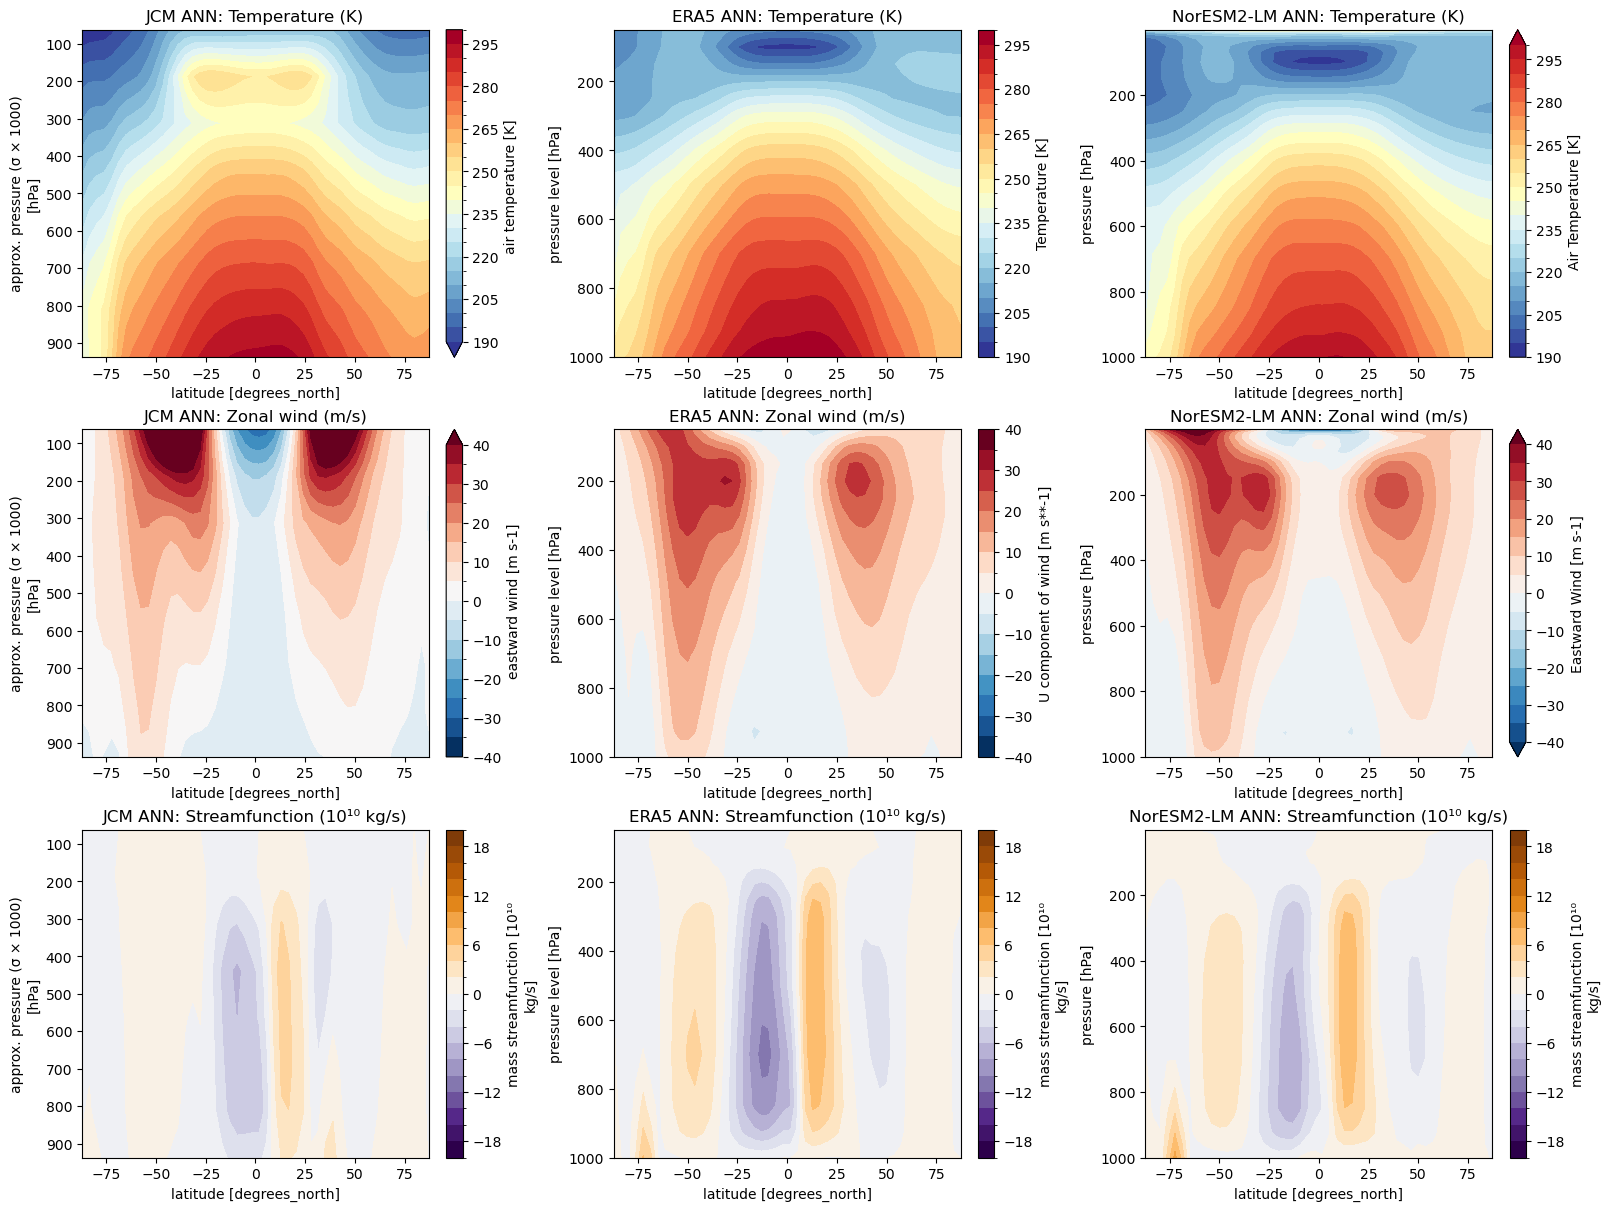

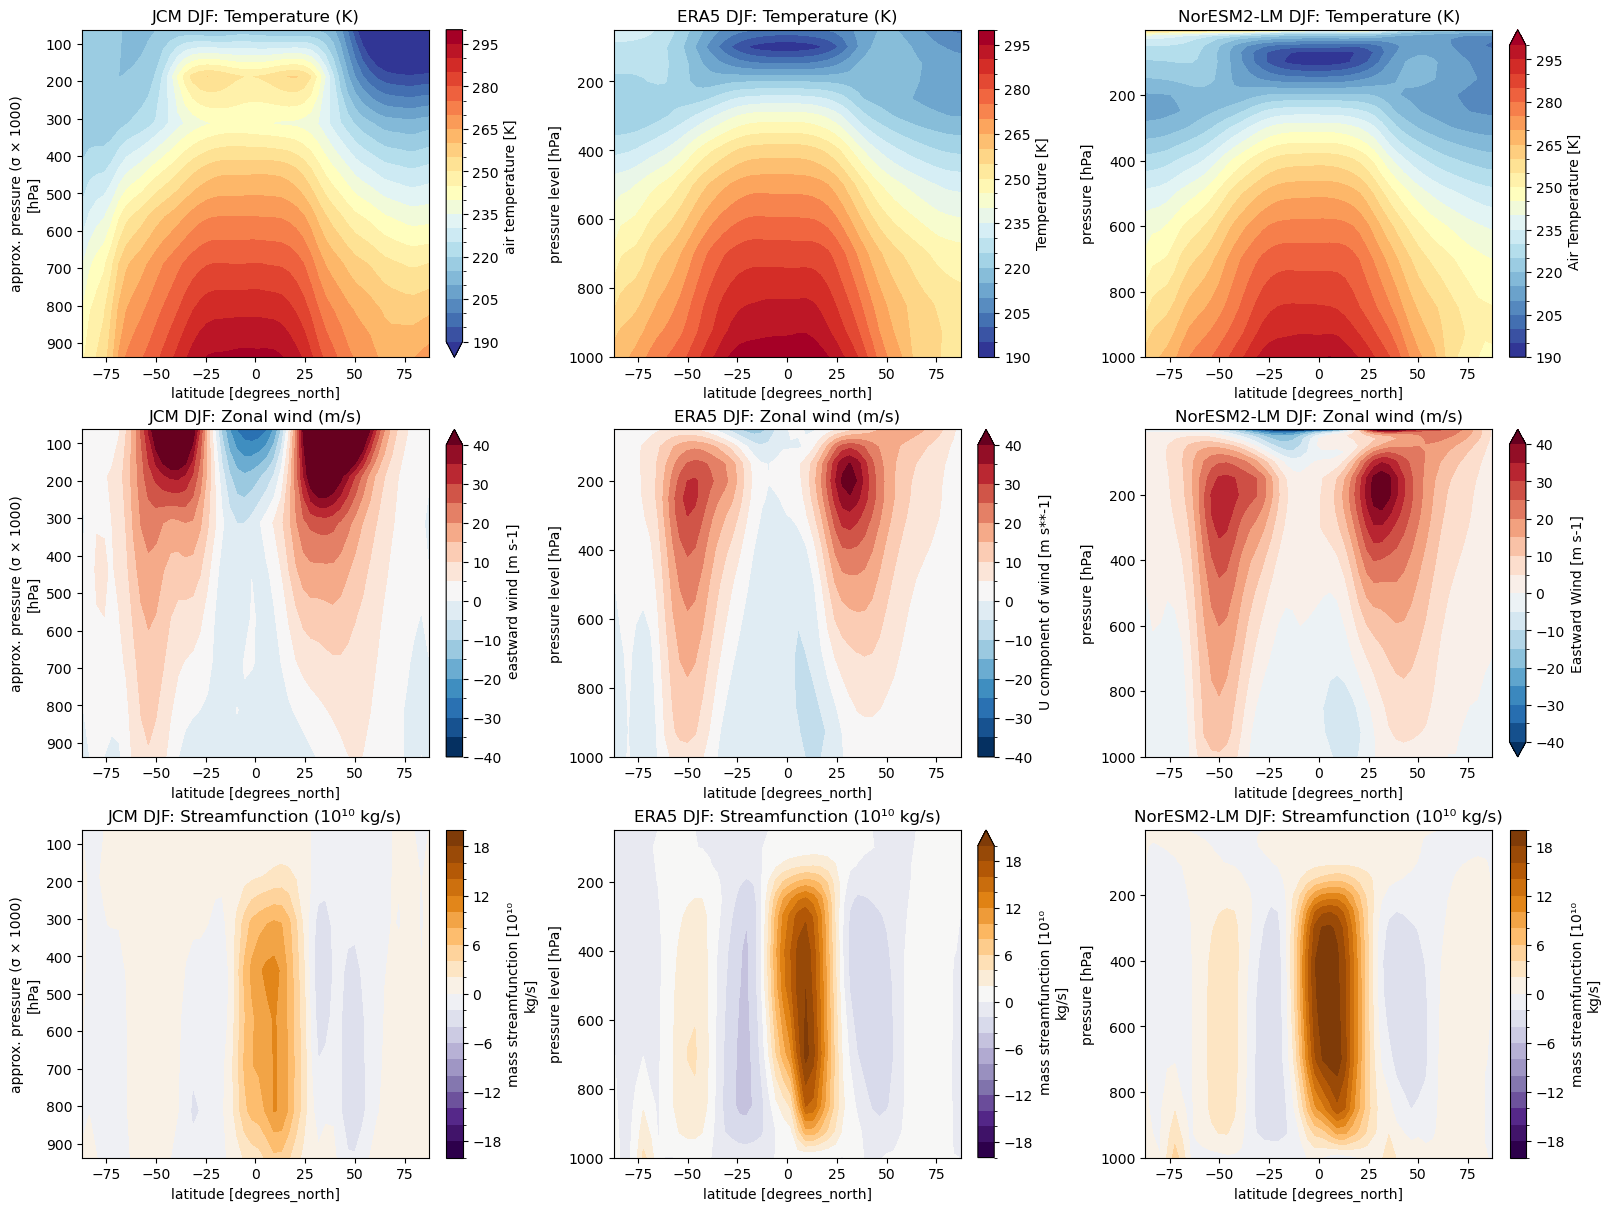

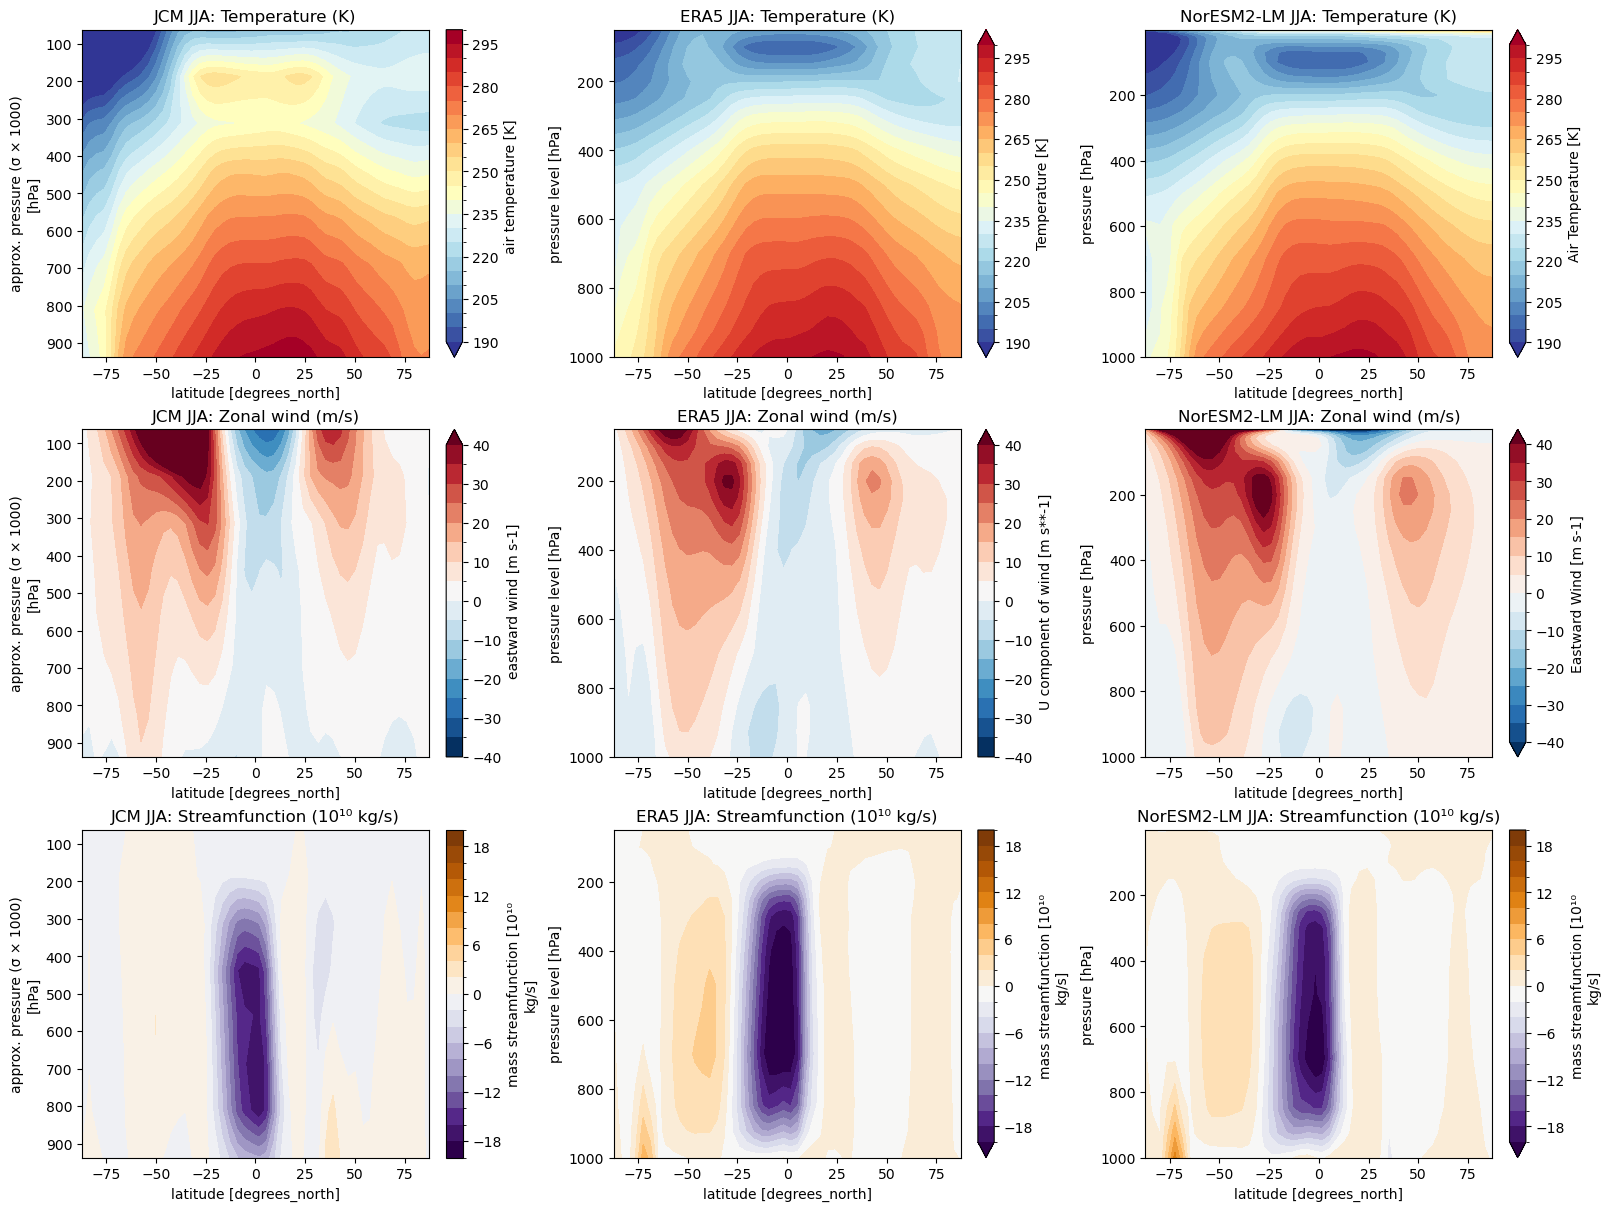

In [19]:
def streamfunction(va, lev):
    """Mean meridional mass streamfunction in 10^10 kg/s (va on pressure levels in hPa)."""
    a, g = 6.371e6, 9.81
    v = va.mean("lon").sortby(lev)                                  # top of atmosphere → surface
    integ = v.cumulative_integrate(coord=lev) * 100.0               # ∫ v dp, hPa → Pa
    psi = 2 * np.pi * a * np.cos(np.deg2rad(v.lat)) / g * integ / 1e10
    return psi.rename("psi").assign_attrs(units="10¹⁰ kg/s", long_name="mass streamfunction")

sources = {"JCM": jcm.swap_dims(level="plev"), "ERA5": era, "NorESM2-LM": nor}

for s in ["ANN", "DJF", "JJA"]:
    fig, axes = plt.subplots(3, 3, figsize=(16, 12), constrained_layout=True)
    for col, (name, src) in enumerate(sources.items()):
        d = season(src, s)
        d["ta"].mean("lon").plot.contourf(ax=axes[0, col], x="lat", y="plev", levels=np.arange(190, 305, 5),
                                          cmap="RdYlBu_r", yincrease=False)
        d["ua"].mean("lon").plot.contourf(ax=axes[1, col], x="lat", y="plev", levels=np.arange(-40, 45, 5),
                                          cmap="RdBu_r", yincrease=False)
        streamfunction(d["va"], "plev").plot.contourf(ax=axes[2, col], x="lat", y="plev",
                                                      levels=np.arange(-20, 22, 2), cmap="PuOr_r",
                                                      yincrease=False)
        for r, t in enumerate(["Temperature (K)", "Zonal wind (m/s)", "Streamfunction (10¹⁰ kg/s)"]):
            axes[r, col].set_title(f"{name} {s}: {t}")
    fig.savefig(f"figures/zonal_{s}.png", dpi=150); plt.show()

### Global-mean Top-of-Atmosphere (TOA) Energy Budget

- Albedo matches ERA5, also close to NorESM2-LM --> overall clouds and surfaces are reflecting reasonable amounts of sunshine
- JCM's incoming SW is a littler higher
- Net TOA is too high

In [20]:
def toa(d):
    a = d.mean("month")
    i, r, o = gm(a.toa_in_sw), gm(a.toa_up_sw), gm(a.olr)
    return {"incoming SW": i, "reflected SW": r, "OLR": o, "net (in − refl − OLR)": i - r - o,
            "albedo": r / i}

budget = pd.DataFrame({"JCM": toa(jcm), "ERA5": toa(era), "NorESM2-LM": toa(nor)}).round(2)
budget.to_csv("figures/toa_budget.csv")
budget

,JCM,ERA5,NorESM2-LM
incoming SW,342.05,340.37,340.23
reflected SW,100.46,97.71,102.06
OLR,236.61,241.98,237.53
net (in − refl − OLR),4.98,0.68,0.65
albedo,0.29,0.29,0.30
